# Telecom Customer Churn Prediction — PySpark ETL + LightGBM

**Author:** Panuwat Wasinanuwat · MSc Data Science, Chiang Mai University

**Goal.** Predict which prepaid telecom customers will churn, rank customers by risk so a retention team can target the
riskiest ones first, and explain what drives the risk.

**Data.** Expresso Churn Prediction Challenge (`Train.csv`): about 2.15 million customers of an African telecom operator,
19 columns describing recharges, revenue, calls by network, data usage and activity over a 90-day window. About 19% churn.

**Approach.**

| Step | What | Why |
|---|---|---|
| 1 | Load and explore with **PySpark / Spark SQL** | Scales to millions of rows; same code runs on a cluster |
| 2 | Row-level feature engineering in Spark | Ratios, activity rate, tenure order, missing-value indicators |
| 3 | Stratified **train / validation / test = 70 / 15 / 15** split *before* any fitted transform | No information from validation/test leaks into training |
| 4 | Baselines: majority class, a one-rule score, logistic regression | A model is only useful if it beats simple alternatives |
| 5 | **LightGBM** with early stopping on validation; ablation of engineered features | Strong tabular model; native handling of missing values and categories |
| 6 | Evaluate with **ROC-AUC, PR-AUC**, threshold chosen on validation, **cumulative gains / lift** | Accuracy is misleading at 19% churn (predicting "no churn" for everyone already gives 81%) |
| 7 | Explain with **SHAP** (TreeSHAP via LightGBM `pred_contrib`) | Which behaviours drive churn risk |

**How to run.** See `README.md`: install `requirements.txt` and Java 17, put `Train.csv` in `data/`, then run all cells
(CPU only, about 20–30 min on 4–8 cores). Figures and `results.json` are written to `outputs/`. If Spark cannot start
(for example, no Java), the notebook falls back to pandas automatically and builds the same features.

## 0. Setup

In [1]:
import os, sys, json, time, shutil, platform, tempfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss,
                             precision_recall_curve, roc_curve, precision_score, recall_score,
                             f1_score, accuracy_score, confusion_matrix)

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
BLUE, ORANGE, GRAY, GREEN = "#2563eb", "#ea580c", "#9ca3af", "#16a34a"

SEED = 42
SAMPLE_FRAC = 1.0     # use e.g. 0.3 on a laptop with less than 16 GB RAM (results then cover 30% of customers)
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


# Resources: respect a Slurm allocation on an HPC node, otherwise use the whole machine.
N_CORES = int(os.environ.get("SLURM_CPUS_PER_TASK") or os.cpu_count() or 4)
if os.environ.get("SLURM_MEM_PER_NODE"):
    MEM_GB = int(os.environ["SLURM_MEM_PER_NODE"]) / 1024
else:
    try:
        MEM_GB = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024**3
    except (ValueError, OSError, AttributeError):   # e.g. Windows
        MEM_GB = 16
SPARK_DRIVER_GB = max(2, min(12, int(MEM_GB * 0.35)))
print(f"Python {platform.python_version()} | cores: {N_CORES} | memory: {MEM_GB:.0f} GB "
      f"| Spark driver: {SPARK_DRIVER_GB} GB | java: {shutil.which('java') or 'NOT FOUND'}")
if MEM_GB < 14 and SAMPLE_FRAC == 1.0:
    print("Warning: less than 16 GB RAM. If the notebook runs out of memory, set SAMPLE_FRAC = 0.3 above.")

RESULTS = {}          # every key number is collected here and saved to results.json at the end
TIMER = {}
T_START = time.time()

Python 3.12.16 | cores: 12 | memory: 24 GB | Spark driver: 8 GB | java: /usr/bin/java


In [2]:
# Looks for data/Train.csv next to the notebook (or one folder up); override with CHURN_DATA=/path/to/Train.csv
candidates = [os.environ.get("CHURN_DATA"), "data/Train.csv", "../data/Train.csv"]
DATA_PATH = next((p for p in candidates if p and os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("Train.csv not found. Download the Expresso churn data (see README) into data/Train.csv, "
                            "or set the CHURN_DATA environment variable.")
print("Data:", os.path.abspath(DATA_PATH))

# Explicit schema: no type guessing, and one pass over the file instead of two.
SCHEMA_DDL = ("user_id STRING, REGION STRING, TENURE STRING, MONTANT DOUBLE, FREQUENCE_RECH DOUBLE, "
              "REVENUE DOUBLE, ARPU_SEGMENT DOUBLE, FREQUENCE DOUBLE, DATA_VOLUME DOUBLE, ON_NET DOUBLE, "
              "ORANGE DOUBLE, TIGO DOUBLE, ZONE1 DOUBLE, ZONE2 DOUBLE, MRG STRING, REGULARITY INT, "
              "TOP_PACK STRING, FREQ_TOP_PACK DOUBLE, CHURN INT")
PANDAS_DTYPES = {name: {"STRING": "object", "DOUBLE": "float64", "INT": "int64"}[typ]
                 for name, typ in (field.split() for field in SCHEMA_DDL.split(", "))}

USE_SPARK = True
try:
    from pyspark.sql import SparkSession, functions as F
    os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")
    spark = (SparkSession.builder.appName("expresso-churn").master(f"local[{N_CORES}]")
             .config("spark.driver.memory", f"{SPARK_DRIVER_GB}g")
             .config("spark.local.dir", os.environ.get("TMPDIR", tempfile.gettempdir()))
             .config("spark.sql.ansi.enabled", "false")
             .config("spark.sql.shuffle.partitions", "16")
             .config("spark.sql.execution.arrow.pyspark.enabled", "true")
             .config("spark.driver.host", "127.0.0.1")
             .config("spark.driver.bindAddress", "127.0.0.1")
             .config("spark.driver.maxResultSize", "4g")
             .getOrCreate())
    spark.sparkContext.setLogLevel("ERROR")
    spark.range(10).count()            # smoke test: fails here (not later) if Java/Spark is broken
    print("Spark", spark.version, "| cores:", spark.sparkContext.defaultParallelism)
except Exception as e:  # e.g. pyspark not installed, or no Java (on HPC: `module load java`)
    USE_SPARK = False
    print("PySpark unavailable -> using the pandas fallback.", repr(e)[:200])

Data: /Users/grizzly/Downloads/churn-repo/data/Train.csv


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/28 23:17:46 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/28 23:17:46 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


26/10/28 23:17:46 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Spark 4.2.1 | cores: 12


## 1. Load and explore with Spark SQL

The raw table is registered as a SQL view (`raw`) so the exploration is written as plain SQL. Each query has a pandas
equivalent that runs only if Spark is unavailable.

In [3]:
t0 = time.time()
if USE_SPARK:
    sdf = spark.read.csv(DATA_PATH, header=True, schema=SCHEMA_DDL)
    if SAMPLE_FRAC < 1.0:
        sdf = sdf.sample(fraction=SAMPLE_FRAC, seed=SEED)
    sdf.createOrReplaceTempView("raw")
else:
    raw = pd.read_csv(DATA_PATH, dtype=PANDAS_DTYPES)
    if SAMPLE_FRAC < 1.0:
        raw = raw.sample(frac=SAMPLE_FRAC, random_state=SEED)


def sql_or_pandas(query, pandas_fn):
    # Run a Spark SQL query, or the equivalent pandas function when Spark is not available.
    return spark.sql(query).toPandas() if USE_SPARK else pandas_fn()


overview = sql_or_pandas(
    "SELECT COUNT(*) AS n_customers, AVG(CHURN) AS churn_rate, COUNT(DISTINCT REGION) AS n_regions, "
    "COUNT(DISTINCT TOP_PACK) AS n_top_packs, COUNT(DISTINCT MRG) AS n_mrg_values FROM raw",
    lambda: pd.DataFrame([{"n_customers": len(raw), "churn_rate": raw["CHURN"].mean(),
                           "n_regions": raw["REGION"].nunique(), "n_top_packs": raw["TOP_PACK"].nunique(),
                           "n_mrg_values": raw["MRG"].nunique()}]))
display(overview)
N_ROWS = int(overview.loc[0, "n_customers"])
CHURN_RATE = float(overview.loc[0, "churn_rate"])
RESULTS["data"] = {"n_customers": N_ROWS, "sample_frac": SAMPLE_FRAC, "churn_rate": round(CHURN_RATE, 4),
                   "majority_class_accuracy": round(1 - CHURN_RATE, 4)}
print(f"Predicting 'no churn' for everyone already gives accuracy {1 - CHURN_RATE:.1%} -> accuracy is not a useful metric here.")

,n_customers,churn_rate,n_regions,n_top_packs,n_mrg_values
0,2154048,0.1875,14,140,1


Predicting 'no churn' for everyone already gives accuracy 81.2% -> accuracy is not a useful metric here.


In [4]:
ALL_COLS = [f.split()[0] for f in SCHEMA_DDL.split(", ")]
missing = sql_or_pandas(
    "SELECT " + ", ".join(f"AVG(CASE WHEN {c} IS NULL THEN 1.0 ELSE 0.0 END) AS {c}" for c in ALL_COLS) + " FROM raw",
    lambda: raw[ALL_COLS].isna().mean().to_frame().T)
missing = missing.T.rename(columns={0: "missing_rate"}).sort_values("missing_rate", ascending=False)

by_regularity = sql_or_pandas(
    "SELECT REGULARITY, COUNT(*) AS n, AVG(CHURN) AS churn_rate FROM raw GROUP BY REGULARITY ORDER BY REGULARITY",
    lambda: raw.groupby("REGULARITY")["CHURN"].agg(n="size", churn_rate="mean").reset_index())

by_tenure = sql_or_pandas(
    "SELECT TENURE, COUNT(*) AS n, AVG(CHURN) AS churn_rate FROM raw GROUP BY TENURE ORDER BY TENURE",
    lambda: raw.groupby("TENURE")["CHURN"].agg(n="size", churn_rate="mean").reset_index())

by_revenue_record = sql_or_pandas(
    "SELECT CASE WHEN REVENUE IS NULL THEN 'no revenue record' ELSE 'has revenue record' END AS segment, "
    "COUNT(*) AS n, AVG(CHURN) AS churn_rate FROM raw GROUP BY 1 ORDER BY 1",
    lambda: (raw.assign(segment=np.where(raw["REVENUE"].isna(), "no revenue record", "has revenue record"))
                .groupby("segment")["CHURN"].agg(n="size", churn_rate="mean").reset_index()))
display(by_revenue_record)
TIMER["load_and_eda_s"] = round(time.time() - t0, 1)

,segment,n,churn_rate
0,has revenue record,1428000,0.0541
1,no revenue record,726048,0.4501


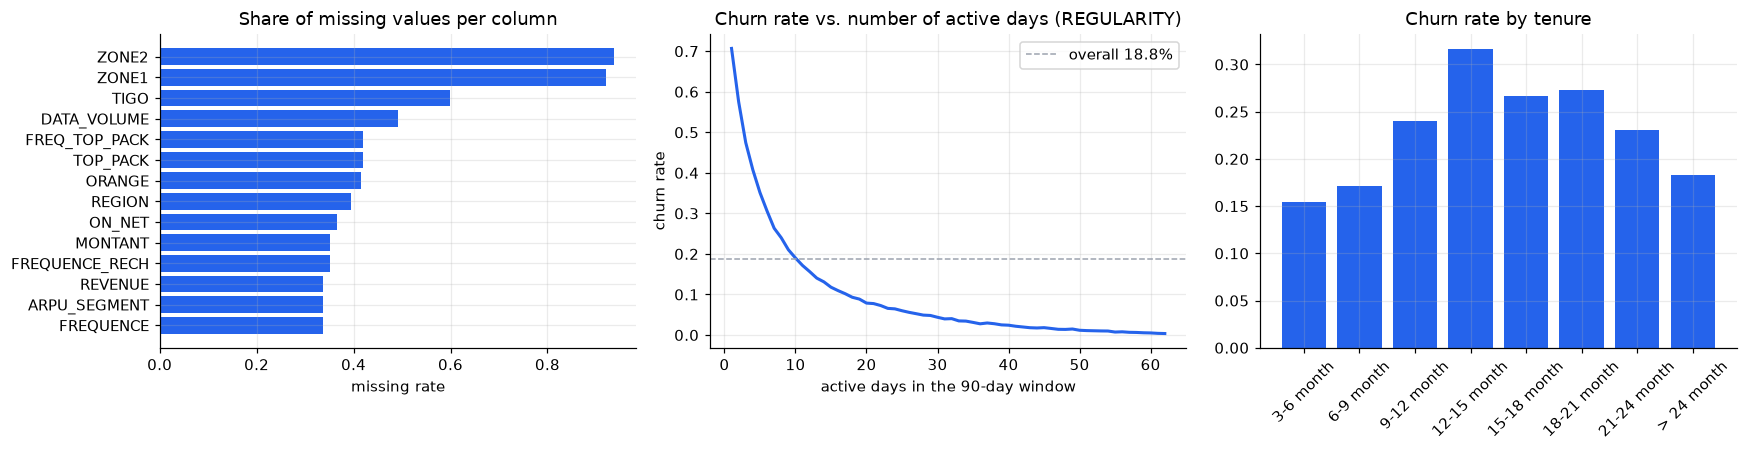

{
  "churn_rate_regularity_le5": 0.5616,
  "churn_rate_regularity_ge50": 0.0062,
  "churn_rate_no_revenue_record": 0.4501,
  "churn_rate_has_revenue_record": 0.0541
}


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

m = missing[missing["missing_rate"] > 0]
axes[0].barh(m.index[::-1], m["missing_rate"][::-1], color=BLUE)
axes[0].set_title("Share of missing values per column")
axes[0].set_xlabel("missing rate")

axes[1].plot(by_regularity["REGULARITY"], by_regularity["churn_rate"], color=BLUE, lw=2)
axes[1].axhline(CHURN_RATE, color=GRAY, ls="--", lw=1, label=f"overall {CHURN_RATE:.1%}")
axes[1].set_title("Churn rate vs. number of active days (REGULARITY)")
axes[1].set_xlabel("active days in the 90-day window")
axes[1].set_ylabel("churn rate")
axes[1].legend()

axes[2].bar(by_tenure["TENURE"].str[2:], by_tenure["churn_rate"], color=BLUE)
axes[2].set_title("Churn rate by tenure")
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout()
save_fig(fig, "01_eda")
plt.show()

low = by_regularity[by_regularity["REGULARITY"] <= 5]
high = by_regularity[by_regularity["REGULARITY"] >= 50]
RESULTS["eda"] = {
    "churn_rate_regularity_le5": round(float(np.average(low["churn_rate"], weights=low["n"])), 4),
    "churn_rate_regularity_ge50": round(float(np.average(high["churn_rate"], weights=high["n"])), 4),
    "churn_rate_no_revenue_record": round(float(by_revenue_record.set_index("segment").loc["no revenue record", "churn_rate"]), 4),
    "churn_rate_has_revenue_record": round(float(by_revenue_record.set_index("segment").loc["has revenue record", "churn_rate"]), 4),
}
print(json.dumps(RESULTS["eda"], indent=2))

**What the exploration shows**

* Missing values are not random noise: a missing `REVENUE`, `MONTANT` or `DATA_VOLUME` means the customer did not recharge,
  spend or use data in the window. Filling them with the column mean (a common shortcut) would erase that signal, so the
  model below keeps them as missing (LightGBM handles this natively) and adds explicit missing-value indicators.
* Churn falls steeply as the number of active days (`REGULARITY`) rises, so activity is expected to be the strongest driver.
* `MRG` has a single value and `user_id` is an identifier, so both are dropped.

## 2. Feature engineering (row-level, in Spark)

Only transformations that use **one row at a time** are done here, so they cannot leak information between customers.
Anything that is *fitted* (category grouping, imputation, scaling) is fitted on the training split only, in Section 3.

| Feature | Definition | Idea |
|---|---|---|
| `TENURE_ORD` | tenure band as an ordered integer (0 = 3–6 months … 7 = >24 months) | keeps the order of the bands |
| `N_MISSING_USAGE` | number of the 13 usage columns that are empty | how inactive the customer is overall |
| `MISS_*` | 1 if the column is empty | explicit "no activity" flags |
| `ACTIVE_RATE` | `REGULARITY / 62` (62 = maximum observed) | share of days active |
| `REV_PER_TXN` | `REVENUE / FREQUENCE` | spend per transaction |
| `TOPUP_AVG` | `MONTANT / FREQUENCE_RECH` | average recharge amount |
| `ONNET_SHARE` | `ON_NET / (ON_NET + ORANGE + TIGO)` | how much the customer calls inside the network |
| `DATA_PER_REV` | `DATA_VOLUME / REVENUE` | data intensity of spending |
| `PACK_SHARE` | `FREQ_TOP_PACK / FREQUENCE` | reliance on the favourite pack |
| `REV_PER_ACTIVE_DAY` | `REVENUE / REGULARITY` | spend per active day |

Every ratio is left empty when its denominator is zero or missing.

In [6]:
RAW_NUM = ["MONTANT", "FREQUENCE_RECH", "REVENUE", "ARPU_SEGMENT", "FREQUENCE", "DATA_VOLUME", "ON_NET",
           "ORANGE", "TIGO", "ZONE1", "ZONE2", "REGULARITY", "FREQ_TOP_PACK"]
CAT = ["REGION", "TOP_PACK"]
USAGE_COLS = ["MONTANT", "FREQUENCE_RECH", "REVENUE", "ARPU_SEGMENT", "FREQUENCE", "DATA_VOLUME", "ON_NET",
              "ORANGE", "TIGO", "ZONE1", "ZONE2", "TOP_PACK", "FREQ_TOP_PACK"]
MISS_COLS = ["REGION", "MONTANT", "REVENUE", "DATA_VOLUME", "ON_NET", "TOP_PACK"]
RATIOS = {  # name: (numerator, denominator)
    "REV_PER_TXN": ("REVENUE", "FREQUENCE"),
    "TOPUP_AVG": ("MONTANT", "FREQUENCE_RECH"),
    "DATA_PER_REV": ("DATA_VOLUME", "REVENUE"),
    "PACK_SHARE": ("FREQ_TOP_PACK", "FREQUENCE"),
    "REV_PER_ACTIVE_DAY": ("REVENUE", "REGULARITY"),
}
ENGINEERED = (["N_MISSING_USAGE", "ACTIVE_RATE", "ONNET_SHARE"] + list(RATIOS)
              + [f"MISS_{c}" for c in MISS_COLS])
FEATURES_RAW = RAW_NUM + ["TENURE_ORD"] + CAT        # original columns only (tenure needs an encoding anyway)
FEATURES_FULL = FEATURES_RAW + ENGINEERED


def build_features_spark(sdf):
    def ratio(num, den):
        return F.when(F.col(den) > 0, F.col(num) / F.col(den))

    calls_total = sum(F.coalesce(F.col(c), F.lit(0.0)) for c in ["ON_NET", "ORANGE", "TIGO"])
    exprs = (
        [F.col("CHURN")] + [F.col(c) for c in CAT + RAW_NUM]
        + [(F.ascii(F.substring("TENURE", 1, 1)) - F.lit(ord("D"))).cast("int").alias("TENURE_ORD"),
           sum(F.col(c).isNull().cast("int") for c in USAGE_COLS).alias("N_MISSING_USAGE"),
           (F.col("REGULARITY") / F.lit(62.0)).alias("ACTIVE_RATE"),
           F.when(calls_total > 0, F.coalesce(F.col("ON_NET"), F.lit(0.0)) / calls_total).alias("ONNET_SHARE")]
        + [ratio(n, d).alias(name) for name, (n, d) in RATIOS.items()]
        + [F.col(c).isNull().cast("int").alias(f"MISS_{c}") for c in MISS_COLS]
    )
    return sdf.select(*exprs)


def build_features_pandas(df):
    out = df[["CHURN"] + CAT + RAW_NUM].copy()
    out["TENURE_ORD"] = df["TENURE"].str[0].map(ord) - ord("D")
    out["N_MISSING_USAGE"] = df[USAGE_COLS].isna().sum(axis=1)
    out["ACTIVE_RATE"] = df["REGULARITY"] / 62.0
    calls_total = df[["ON_NET", "ORANGE", "TIGO"]].fillna(0.0).sum(axis=1)
    out["ONNET_SHARE"] = (df["ON_NET"].fillna(0.0) / calls_total).where(calls_total > 0)
    for name, (n, d) in RATIOS.items():
        out[name] = (df[n] / df[d]).where(df[d] > 0)
    for c in MISS_COLS:
        out[f"MISS_{c}"] = df[c].isna().astype("int32")
    return out


t0 = time.time()
if USE_SPARK:
    feat_sdf = build_features_spark(sdf)
    feat_sdf.printSchema()
    pdf = feat_sdf.toPandas()          # ~2.15M rows x 33 columns fits comfortably in memory
    spark.stop()                       # free the JVM memory before modelling
else:
    pdf = build_features_pandas(raw)
    del raw
for c in ["TENURE_ORD", "N_MISSING_USAGE"] + [f"MISS_{c}" for c in MISS_COLS] + ["CHURN"]:
    pdf[c] = pdf[c].astype("int32")
TIMER["feature_engineering_s"] = round(time.time() - t0, 1)
print(pdf.shape, f"| {TIMER['feature_engineering_s']} s")
pdf.head()

root
 |-- CHURN: integer (nullable = true)
 |-- REGION: string (nullable = true)
 |-- TOP_PACK: string (nullable = true)
 |-- MONTANT: double (nullable = true)
 |-- FREQUENCE_RECH: double (nullable = true)
 |-- REVENUE: double (nullable = true)
 |-- ARPU_SEGMENT: double (nullable = true)
 |-- FREQUENCE: double (nullable = true)
 |-- DATA_VOLUME: double (nullable = true)
 |-- ON_NET: double (nullable = true)
 |-- ORANGE: double (nullable = true)
 |-- TIGO: double (nullable = true)
 |-- ZONE1: double (nullable = true)
 |-- ZONE2: double (nullable = true)
 |-- REGULARITY: integer (nullable = true)
 |-- FREQ_TOP_PACK: double (nullable = true)
 |-- TENURE_ORD: integer (nullable = true)
 |-- N_MISSING_USAGE: integer (nullable = false)
 |-- ACTIVE_RATE: double (nullable = true)
 |-- ONNET_SHARE: double (nullable = true)
 |-- REV_PER_TXN: double (nullable = true)
 |-- TOPUP_AVG: double (nullable = true)
 |-- DATA_PER_REV: double (nullable = true)
 |-- PACK_SHARE: double (nullable = true)
 |-- 

(2154048, 31) | 2.4 s


,CHURN,REGION,TOP_PACK,MONTANT,FREQUENCE_RECH,REVENUE,ARPU_SEGMENT,FREQUENCE,DATA_VOLUME,ON_NET,...,TOPUP_AVG,DATA_PER_REV,PACK_SHARE,REV_PER_ACTIVE_DAY,MISS_REGION,MISS_MONTANT,MISS_REVENUE,MISS_DATA_VOLUME,MISS_ON_NET,MISS_TOP_PACK
0,0,FATICK,On net 200F=Unlimited _call24H,"4,250.0000",15.0000,"4,251.0000","1,417.0000",17.0000,4.0000,388.0000,...,283.3333,0.0009,0.4706,78.7222,0,0,0,0,0,0
1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1,1,1,1,1,1
2,0,NaN,On-net 1000F=10MilF;10d,"3,600.0000",2.0000,"1,020.0000",340.0000,2.0000,NaN,90.0000,...,"1,800.0000",NaN,0.5000,60.0000,1,0,0,1,0,0
3,0,DAKAR,"Data:1000F=5GB,7d","13,500.0000",15.0000,"13,502.0000","4,501.0000",18.0000,"43,804.0000",41.0000,...,900.0000,3.2443,0.6111,217.7742,0,0,0,0,0,0
4,0,DAKAR,Mixt 250F=Unlimited_call24H,"1,000.0000",1.0000,985.0000,328.0000,1.0000,NaN,39.0000,...,"1,000.0000",NaN,2.0000,89.5455,0,0,0,1,0,0


In [7]:
# Customers with every usage field empty are effectively inactive. How often do they churn?
inactive = pdf.groupby("N_MISSING_USAGE")["CHURN"].agg(n="size", churn_rate="mean")
display(inactive)
RESULTS["eda"]["share_all_usage_missing"] = round(float((pdf["N_MISSING_USAGE"] == len(USAGE_COLS)).mean()), 4)
RESULTS["eda"]["churn_rate_all_usage_missing"] = round(float(inactive.loc[len(USAGE_COLS), "churn_rate"]), 4) \
    if len(USAGE_COLS) in inactive.index else None

,n,churn_rate
N_MISSING_USAGE,,
0,13166,0.0200
1,119509,0.0243
2,485028,0.0256
3,405199,0.0369
4,194221,0.0695
5,90354,0.1078
6,48526,0.1032
7,27187,0.1284
8,15665,0.1996


## 3. Leak-free split and fitted preprocessing

* Stratified split **70 / 15 / 15**: training, validation (early stopping and threshold choice), and a test set that is used
  **once**, for the final numbers.
* Rare `TOP_PACK` values (fewer than 500 training customers) are grouped into `OTHER`, using counts from the **training split
  only**. Categories unseen in training also become `OTHER`.
* No imputation for LightGBM: missing values stay missing. The logistic-regression baseline gets median imputation, fitted on
  training data inside its pipeline.

In [8]:
train_df, temp_df = train_test_split(pdf, test_size=0.30, stratify=pdf["CHURN"], random_state=SEED)
valid_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["CHURN"], random_state=SEED)
del temp_df, pdf

MIN_CAT_COUNT = 500
CAT_LEVELS = {}
for c in CAT:
    counts = train_df[c].value_counts()
    CAT_LEVELS[c] = sorted(counts[counts >= MIN_CAT_COUNT].index.tolist())


def apply_categories(df):
    df = df.copy()
    for c in CAT:
        keep = df[c].isin(CAT_LEVELS[c]) | df[c].isna()
        df[c] = pd.Categorical(df[c].where(keep, "OTHER"), categories=CAT_LEVELS[c] + ["OTHER"])
    return df


train_df, valid_df, test_df = (apply_categories(d) for d in (train_df, valid_df, test_df))
y_train, y_valid, y_test = (d["CHURN"].to_numpy() for d in (train_df, valid_df, test_df))

split_info = pd.DataFrame({"rows": [len(train_df), len(valid_df), len(test_df)],
                           "churn_rate": [y_train.mean(), y_valid.mean(), y_test.mean()]},
                          index=["train", "valid", "test"])
display(split_info)
print({c: len(v) for c, v in CAT_LEVELS.items()}, "category levels kept (plus OTHER)")
RESULTS["split"] = {"train": len(train_df), "valid": len(valid_df), "test": len(test_df)}

,rows,churn_rate
train,1507833,0.1875
valid,323107,0.1875
test,323108,0.1875


{'REGION': 14, 'TOP_PACK': 41} category levels kept (plus OTHER)


## 4. Evaluation helpers and simple baselines

Metrics reported on the **test set**:

* **ROC-AUC** — probability that a random churner is ranked above a random non-churner (0.5 = random).
* **PR-AUC** (average precision) — focuses on the churn class; the random level equals the churn rate (~0.19).
* **Log loss / Brier** — quality of the predicted probabilities (lower is better).
* **Precision, recall, F1** at a threshold chosen on the **validation** set (maximum F1), never on the test set.

In [9]:
MODEL_ROWS = []


def evaluate(name, y_true, score, is_probability=True, threshold=None):
    row = {"model": name,
           "roc_auc": roc_auc_score(y_true, score),
           "pr_auc": average_precision_score(y_true, score)}
    if is_probability:
        row["log_loss"] = log_loss(y_true, np.clip(score, 1e-7, 1 - 1e-7))
        row["brier"] = brier_score_loss(y_true, score)
    if threshold is not None:
        pred = (score >= threshold).astype(int)
        row.update({"threshold": threshold, "precision": precision_score(y_true, pred, zero_division=0),
                    "recall": recall_score(y_true, pred), "f1": f1_score(y_true, pred),
                    "accuracy": accuracy_score(y_true, pred)})
    MODEL_ROWS.append(row)
    return row


def best_f1_threshold(y_true, score):
    prec, rec, thr = precision_recall_curve(y_true, score)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.nanargmax(f1)])


# Baseline 1: majority class (everyone stays). Scores are constant -> AUC 0.5 by definition.
MODEL_ROWS.append({"model": "Majority class (no model)", "roc_auc": 0.5, "pr_auc": float(y_test.mean()),
                   "accuracy": 1 - float(y_test.mean()), "recall": 0.0, "f1": 0.0})

# Baseline 2: one business rule - fewer active days = higher risk.
rule_score_test = -test_df["REGULARITY"].to_numpy(dtype=float)
evaluate("Rule: fewer active days = higher risk", y_test, rule_score_test, is_probability=False)
pd.DataFrame(MODEL_ROWS)

,model,roc_auc,pr_auc,accuracy,recall,f1
0,Majority class (no model),0.5000,0.1875,0.8125,0.0000,0.0000
1,Rule: fewer active days = higher risk,0.8893,0.5997,NaN,NaN,NaN


### Logistic regression baseline

A linear model with a proper pipeline: median imputation with missing indicators, `log1p` for the heavily skewed amounts,
standardisation, and one-hot encoding of the categories. Everything is fitted on the training split.

In [10]:
t0 = time.time()
NUM_FULL = [c for c in FEATURES_FULL if c not in CAT]


def lr_frame(df):
    out = df[NUM_FULL + CAT].copy()
    for c in CAT:
        out[c] = out[c].astype(object)
    return out


lr_model = Pipeline([
    ("prep", ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("log", FunctionTransformer(np.log1p)),
                          ("scale", StandardScaler())]), NUM_FULL),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="MISSING")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CAT),
    ])),
    ("clf", LogisticRegression(max_iter=500, C=1.0)),
])
lr_model.fit(lr_frame(train_df), y_train)
p_valid_lr = lr_model.predict_proba(lr_frame(valid_df))[:, 1]
p_test_lr = lr_model.predict_proba(lr_frame(test_df))[:, 1]
thr_lr = best_f1_threshold(y_valid, p_valid_lr)
evaluate("Logistic regression", y_test, p_test_lr, threshold=thr_lr)
TIMER["logistic_regression_s"] = round(time.time() - t0, 1)
pd.DataFrame(MODEL_ROWS)

,model,roc_auc,pr_auc,accuracy,recall,f1,log_loss,brier,threshold,precision
0,Majority class (no model),0.5000,0.1875,0.8125,0.0000,0.0000,NaN,NaN,NaN,NaN
1,Rule: fewer active days = higher risk,0.8893,0.5997,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Logistic regression,0.9295,0.6963,0.8686,0.8021,0.6960,0.2561,0.0829,0.3474,0.6146


## 5. LightGBM

Gradient-boosted trees with early stopping on the validation AUC. LightGBM routes missing values and `category` columns
natively. Two versions are trained to measure what the engineered features add:

* **raw** — original columns only;
* **full** — original columns + engineered features.

In [11]:
LGB_PARAMS = dict(objective="binary", metric="auc", learning_rate=0.05, num_leaves=63, min_child_samples=200,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                  n_estimators=3000, random_state=SEED, n_jobs=N_CORES, verbose=-1)


def train_lgb(features):
    model = lgb.LGBMClassifier(**LGB_PARAMS)
    model.fit(train_df[features], y_train,
              eval_set=[(valid_df[features], y_valid)],
              callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(250)])
    return model


LGB_MODELS, LGB_SCORES = {}, {}
for tag, feats in [("raw", FEATURES_RAW), ("full", FEATURES_FULL)]:
    t0 = time.time()
    model = train_lgb(feats)
    p_valid = model.predict_proba(valid_df[feats])[:, 1]
    p_test = model.predict_proba(test_df[feats])[:, 1]
    thr = best_f1_threshold(y_valid, p_valid)
    evaluate(f"LightGBM ({tag} features)", y_test, p_test, threshold=thr)
    LGB_MODELS[tag], LGB_SCORES[tag] = model, {"valid": p_valid, "test": p_test, "threshold": thr}
    TIMER[f"lightgbm_{tag}_s"] = round(time.time() - t0, 1)
    print(f"{tag}: best iteration {model.best_iteration_}, {TIMER[f'lightgbm_{tag}_s']} s")

best_lgb = LGB_MODELS["full"]
p_test_lgb = LGB_SCORES["full"]["test"]
THRESHOLD = LGB_SCORES["full"]["threshold"]

[250]	valid_0's auc: 0.931744


raw: best iteration 264, 11.2 s


[250]	valid_0's auc: 0.93176


full: best iteration 279, 12.2 s


## 6. Results on the test set

In [12]:
results_table = pd.DataFrame(MODEL_ROWS).set_index("model")
cols = [c for c in ["roc_auc", "pr_auc", "log_loss", "brier", "threshold", "precision", "recall", "f1", "accuracy"]
        if c in results_table]
results_table = results_table[cols]
display(results_table)
RESULTS["models"] = results_table.reset_index().round(4).replace({np.nan: None}).to_dict(orient="records")
RESULTS["lightgbm_best_iteration"] = int(best_lgb.best_iteration_)

,roc_auc,pr_auc,log_loss,brier,threshold,precision,recall,f1,accuracy
model,,,,,,,,,
Majority class (no model),0.5000,0.1875,NaN,NaN,NaN,NaN,0.0000,0.0000,0.8125
Rule: fewer active days = higher risk,0.8893,0.5997,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Logistic regression,0.9295,0.6963,0.2561,0.0829,0.3474,0.6146,0.8021,0.6960,0.8686
LightGBM (raw features),0.9313,0.7034,0.2515,0.0816,0.3298,0.6041,0.8263,0.6979,0.8659
LightGBM (full features),0.9314,0.7035,0.2514,0.0816,0.3434,0.6095,0.8178,0.6985,0.8676


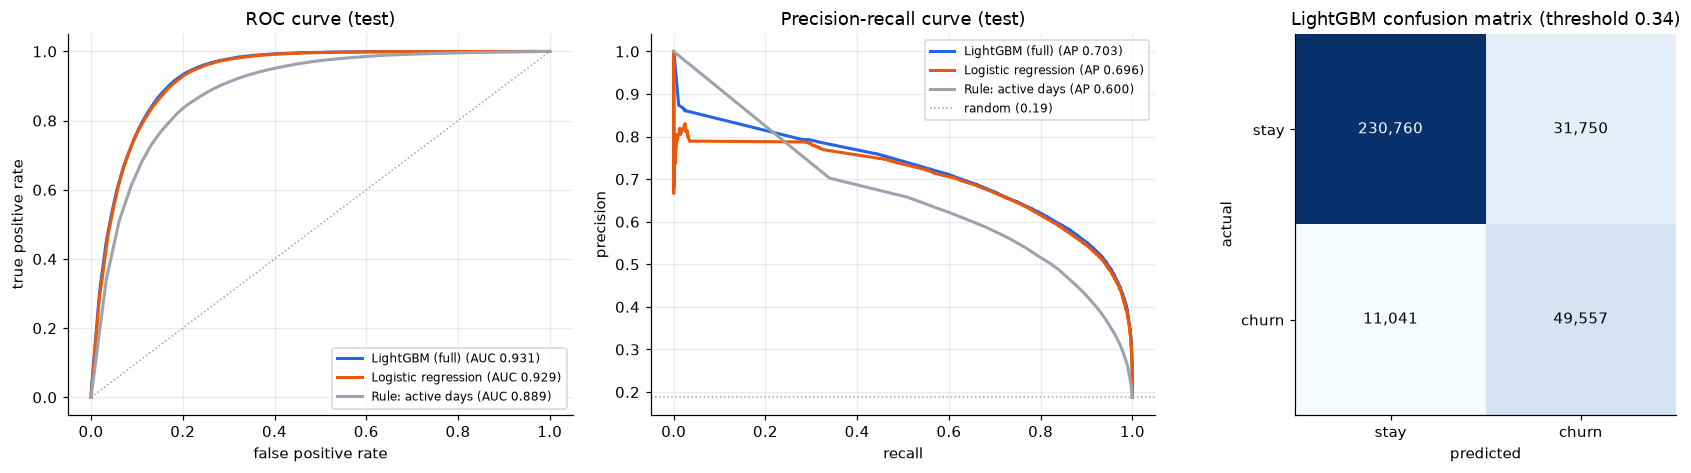

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
curves = [("LightGBM (full)", p_test_lgb, BLUE), ("Logistic regression", p_test_lr, ORANGE),
          ("Rule: active days", rule_score_test, GRAY)]

for name, s, col in curves:
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=col, lw=2, label=f"{name} (AUC {roc_auc_score(y_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], color=GRAY, ls=":", lw=1)
axes[0].set(title="ROC curve (test)", xlabel="false positive rate", ylabel="true positive rate")
axes[0].legend(loc="lower right", fontsize=8)

for name, s, col in curves:
    prec, rec, _ = precision_recall_curve(y_test, s)
    axes[1].plot(rec, prec, color=col, lw=2, label=f"{name} (AP {average_precision_score(y_test, s):.3f})")
axes[1].axhline(y_test.mean(), color=GRAY, ls=":", lw=1, label=f"random ({y_test.mean():.2f})")
axes[1].set(title="Precision-recall curve (test)", xlabel="recall", ylabel="precision")
axes[1].legend(loc="upper right", fontsize=8)

cm = confusion_matrix(y_test, (p_test_lgb >= THRESHOLD).astype(int))
axes[2].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[2].text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
axes[2].set(title=f"LightGBM confusion matrix (threshold {THRESHOLD:.2f})", xticks=[0, 1], yticks=[0, 1],
            xticklabels=["stay", "churn"], yticklabels=["stay", "churn"], xlabel="predicted", ylabel="actual")
axes[2].grid(False)
plt.tight_layout()
save_fig(fig, "02_roc_pr_confusion")
plt.show()

## 7. Business view: who should the retention team call first?

A retention campaign cannot contact everyone. The useful question is: **if we contact only the top X% of customers ranked
by predicted risk, what share of all churners do we reach?** (cumulative gains), and how much better is that than picking
customers at random (lift).

,top_%,churn_rate_in_band,cum_churners_captured_%,cum_lift
0,10.0000,0.7663,40.8578,4.0858
1,20.0000,0.5641,70.9380,3.5469
2,30.0000,0.3429,89.2208,2.9740
3,40.0000,0.1454,96.9735,2.4243
4,50.0000,0.0413,99.1732,1.9835
5,60.0000,0.0110,99.7574,1.6626
6,70.0000,0.0032,99.9257,1.4275
7,80.0000,0.0010,99.9769,1.2497
8,90.0000,0.0003,99.9950,1.1111
9,100.0000,0.0001,100.0000,1.0000


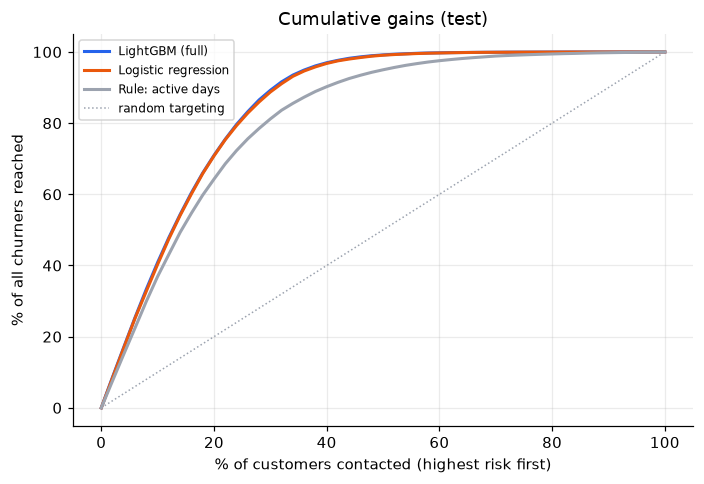

{
  "top_10pct": {
    "churners_captured_pct": 40.9,
    "lift": 4.09,
    "churn_rate_in_band": 0.7663
  },
  "top_20pct": {
    "churners_captured_pct": 70.9,
    "lift": 3.55,
    "churn_rate_in_band": 0.5641
  },
  "top_30pct": {
    "churners_captured_pct": 89.2,
    "lift": 2.97,
    "churn_rate_in_band": 0.3429
  }
}


In [14]:
def gains_table(y_true, score, n_bins=10):
    order = np.argsort(-score, kind="stable")
    y_sorted = np.asarray(y_true)[order]
    n, total = len(y_sorted), y_sorted.sum()
    rows = []
    for k in range(1, n_bins + 1):
        lo, hi = int(round(n * (k - 1) / n_bins)), int(round(n * k / n_bins))
        captured = y_sorted[:hi].sum()
        rows.append({"top_%": 100 * k / n_bins,
                     "churn_rate_in_band": y_sorted[lo:hi].mean(),
                     "cum_churners_captured_%": 100 * captured / total,
                     "cum_lift": (captured / hi) / (total / n)})
    return pd.DataFrame(rows)


gains = gains_table(y_test, p_test_lgb)
display(gains)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, s, col in curves:
    g = gains_table(y_test, s, n_bins=50)
    ax.plot([0] + g["top_%"].tolist(), [0] + g["cum_churners_captured_%"].tolist(), color=col, lw=2, label=name)
ax.plot([0, 100], [0, 100], color=GRAY, ls=":", lw=1, label="random targeting")
ax.set(title="Cumulative gains (test)", xlabel="% of customers contacted (highest risk first)",
       ylabel="% of all churners reached")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "03_cumulative_gains")
plt.show()

RESULTS["gains"] = {f"top_{int(r['top_%'])}pct": {"churners_captured_pct": round(r["cum_churners_captured_%"], 1),
                                                    "lift": round(r["cum_lift"], 2),
                                                    "churn_rate_in_band": round(r["churn_rate_in_band"], 4)}
                    for _, r in gains.iterrows() if int(r["top_%"]) in (10, 20, 30)}
print(json.dumps(RESULTS["gains"], indent=2))

## 8. What drives churn risk? (SHAP)

SHAP values split each prediction into the contribution of every feature (in log-odds). They are computed exactly for
tree models by LightGBM itself (`pred_contrib=True`, the TreeSHAP algorithm) on a random sample of 50,000 test customers.

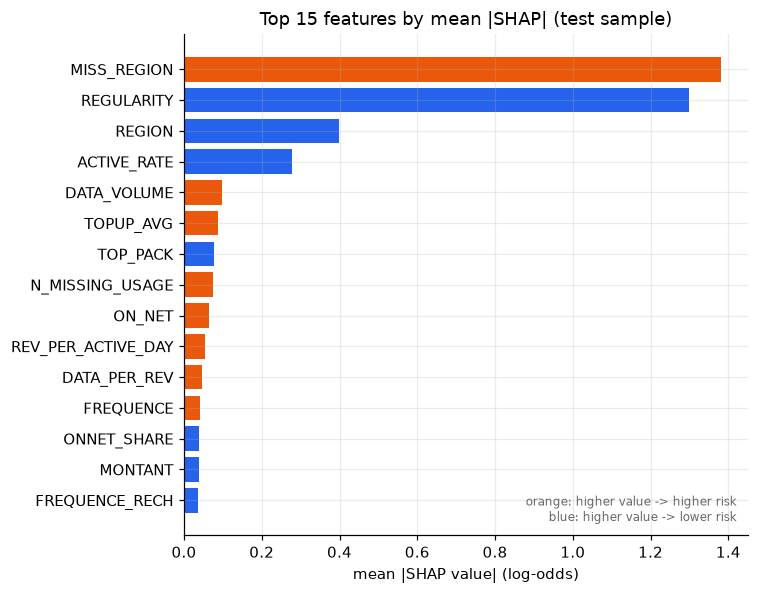

,feature,mean_abs_shap,direction_corr
0,MISS_REGION,1.3814,0.9940
1,REGULARITY,1.2981,-0.9670
2,REGION,0.3978,NaN
3,ACTIVE_RATE,0.2770,-0.9700
4,DATA_VOLUME,0.0985,0.3170
5,TOPUP_AVG,0.0881,0.5210
6,TOP_PACK,0.0764,NaN
7,N_MISSING_USAGE,0.0744,0.8120
8,ON_NET,0.0643,0.3600
9,REV_PER_ACTIVE_DAY,0.0546,0.4160


In [15]:
shap_sample = test_df.sample(min(50_000, len(test_df)), random_state=SEED)
X_shap = shap_sample[FEATURES_FULL]
contrib = best_lgb.predict(X_shap, pred_contrib=True)
shap_values = np.asarray(contrib)[:, :-1]          # last column is the expected value (bias)

importance = (pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES_FULL)
                .sort_values(ascending=False))
# Direction: correlation between a feature's value and its SHAP value (+ = higher value -> higher risk)
direction = {}
for i, c in enumerate(FEATURES_FULL):
    x = X_shap[c].cat.codes.replace(-1, np.nan) if c in CAT else X_shap[c]
    ok = x.notna().to_numpy()
    direction[c] = (np.corrcoef(x.to_numpy(dtype=float)[ok], shap_values[ok, i])[0, 1]
                    if c not in CAT and ok.sum() > 2 and np.nanstd(x[ok]) > 0 else np.nan)

top = importance.head(15)
fig, ax = plt.subplots(figsize=(7, 5.5))
colors = [ORANGE if direction.get(c, 0) > 0 else BLUE for c in top.index[::-1]]
ax.barh(top.index[::-1], top.values[::-1], color=colors)
ax.set(title="Top 15 features by mean |SHAP| (test sample)", xlabel="mean |SHAP value| (log-odds)")
ax.text(0.98, 0.02, "orange: higher value -> higher risk\nblue: higher value -> lower risk",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color="dimgray")
plt.tight_layout()
save_fig(fig, "04_shap_importance")
plt.show()

RESULTS["top_features"] = [{"feature": c, "mean_abs_shap": round(float(v), 4),
                            "direction_corr": None if pd.isna(direction.get(c)) else round(float(direction[c]), 3)}
                           for c, v in importance.head(10).items()]
display(pd.DataFrame(RESULTS["top_features"]))

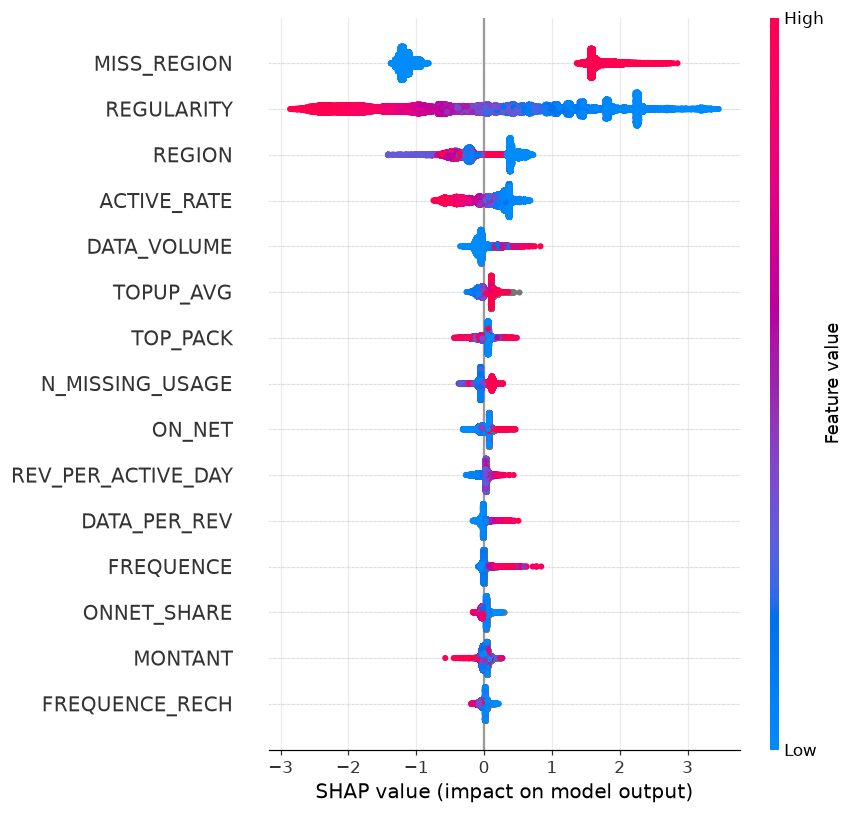

In [16]:
# Optional: the classic SHAP beeswarm plot, if the shap package is installed (it is on Kaggle).
try:
    import shap
    X_plot = X_shap.copy()
    for c in CAT:
        X_plot[c] = X_plot[c].cat.codes
    shap.summary_plot(shap_values, X_plot, max_display=15, show=False)
    save_fig(plt.gcf(), "05_shap_beeswarm")
    plt.show()
except Exception as e:
    print("Beeswarm skipped:", repr(e)[:150])

## 9. Summary

In [17]:
TIMER["total_s"] = round(time.time() - T_START, 1)
RESULTS["runtime_s"] = TIMER
RESULTS["engine"] = "pyspark" if USE_SPARK else "pandas-fallback"

rows = {r["model"]: r for r in RESULTS["models"]}
lgb_row, lr_row = rows["LightGBM (full features)"], rows["Logistic regression"]
raw_row = rows["LightGBM (raw features)"]
g10, g20 = RESULTS["gains"]["top_10pct"], RESULTS["gains"]["top_20pct"]

summary = f'''
Data: {RESULTS["data"]["n_customers"]:,} customers, churn rate {RESULTS["data"]["churn_rate"]:.1%} (ETL engine: {RESULTS["engine"]}).
LightGBM (full): ROC-AUC {lgb_row["roc_auc"]:.4f}, PR-AUC {lgb_row["pr_auc"]:.4f} on {RESULTS["split"]["test"]:,} held-out customers.
  vs logistic regression: ROC-AUC {lr_row["roc_auc"]:.4f}, PR-AUC {lr_row["pr_auc"]:.4f}
  vs LightGBM on raw features only: ROC-AUC {raw_row["roc_auc"]:.4f}, PR-AUC {raw_row["pr_auc"]:.4f}
At the validation-chosen threshold {lgb_row["threshold"]:.2f}: precision {lgb_row["precision"]:.3f}, recall {lgb_row["recall"]:.3f}, F1 {lgb_row["f1"]:.3f}.
Targeting: top 10% riskiest customers contain {g10["churners_captured_pct"]:.1f}% of churners (lift {g10["lift"]:.2f}x);
           top 20% contain {g20["churners_captured_pct"]:.1f}% (lift {g20["lift"]:.2f}x).
Top drivers: {", ".join(f["feature"] for f in RESULTS["top_features"][:5])}.
Total runtime: {TIMER["total_s"] / 60:.1f} min.
'''
print(summary)

RESULTS["environment"] = {"python": platform.python_version(), "cores": N_CORES,
                          "pandas": pd.__version__, "lightgbm": lgb.__version__}
with open(OUT_DIR / "results.json", "w") as fh:
    json.dump(RESULTS, fh, indent=2, default=float)
(OUT_DIR / "summary.txt").write_text(summary.strip() + "\n")
print(f"Saved {OUT_DIR}/results.json and {OUT_DIR}/summary.txt")
print(json.dumps(RESULTS, indent=2, default=float))


Data: 2,154,048 customers, churn rate 18.8% (ETL engine: pyspark).
LightGBM (full): ROC-AUC 0.9314, PR-AUC 0.7035 on 323,108 held-out customers.
  vs logistic regression: ROC-AUC 0.9295, PR-AUC 0.6963
  vs LightGBM on raw features only: ROC-AUC 0.9313, PR-AUC 0.7034
At the validation-chosen threshold 0.34: precision 0.610, recall 0.818, F1 0.699.
Targeting: top 10% riskiest customers contain 40.9% of churners (lift 4.09x);
           top 20% contain 70.9% (lift 3.55x).
Top drivers: MISS_REGION, REGULARITY, REGION, ACTIVE_RATE, DATA_VOLUME.
Total runtime: 0.9 min.

Saved outputs/results.json and outputs/summary.txt
{
  "data": {
    "n_customers": 2154048,
    "sample_frac": 1.0,
    "churn_rate": 0.1875,
    "majority_class_accuracy": 0.8125
  },
  "eda": {
    "churn_rate_regularity_le5": 0.5616,
    "churn_rate_regularity_ge50": 0.0062,
    "churn_rate_no_revenue_record": 0.4501,
    "churn_rate_has_revenue_record": 0.0541,
    "share_all_usage_missing": 0.2373,
    "churn_rate_all_

**Notes and limitations**

* The data is a single snapshot without dates, so the split is random rather than time-based. In production, the model should
  be validated on a later period than it was trained on.
* The threshold that maximises F1 is a neutral default. A real campaign would choose it from the cost of a retention offer and
  the value of a saved customer, or simply contact a fixed top-X% of the ranking (Section 7).
* Ratios such as `REV_PER_TXN` are derived from the same 90-day window as the other columns, so they add no information from
  the future.